# Rwanda Medical Drone Delivery: results showcase

A drone based at the Kigali depot serves five rural health centres. Urgent blood and medicine requests expire fast and the battery lasts about three round trips. DQN, REINFORCE, PPO and A2C were trained with TorchRL on the same environment and the same 400k-step budget; this notebook summarises what they learned.

Re-run everything with `uv run python notebooks/build_showcase.py`.

In [1]:
import io
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from environment.custom_env import ACTIONS, OBS_FIELDS, SCENARIOS, DroneDeliveryEnv
from environment.evaluation import BASELINES, TEST_SEED, evaluate
from training.common import load_policy, scored_policy

pd.set_option("display.precision", 1)
ASSETS, LOGS = ROOT / "assets", ROOT / "logs"
NAMES = {"dqn": "DQN", "reinforce": "REINFORCE", "ppo": "PPO", "a2c": "A2C"}

## The environment

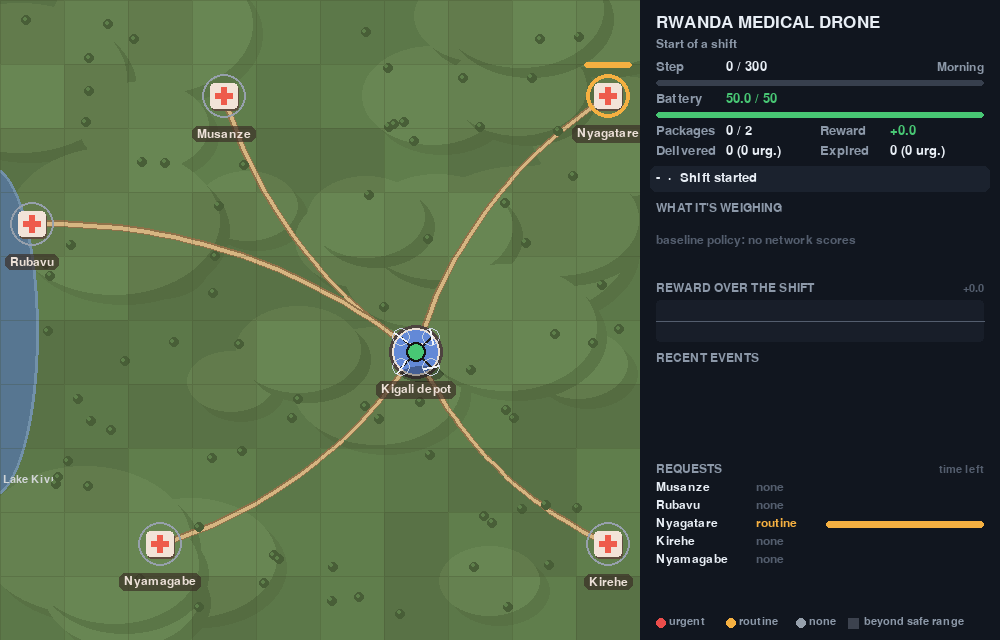

7 actions: north, south, west, east, load, deliver, recharge
32 observations, all scaled to [-1, 1]


In [2]:
env = DroneDeliveryEnv(render_mode="rgb_array")
env.reset(seed=TEST_SEED)
env.label = "Start of a shift"
display(PILImage.fromarray(env.render()))
env.close()
print(f"{len(ACTIONS)} actions: {', '.join(ACTIONS)}")
print(f"{len(OBS_FIELDS)} observations, all scaled to [-1, 1]")

### Where every observation comes from

In [3]:
display(Markdown((ASSETS / "tables" / "observation_map.md").read_text()))

| Index | Field | Meaning | Encoding / range | Simulation rule (real-world source) | Updated | Path to the agent |
|---|---|---|---|---|---|---|
| 0–1 | `drone_x`, `drone_y` | Drone cell on the 10×10 map | cell ÷ 9, in [0, 1] | Changes by one cell on a valid move (GPS fix) | every step | obs vector → TorchRL `observation` → MLP input |
| 2 | `battery` | Remaining charge | battery ÷ 50, in [0, 1] | −1 per airborne step (flying or hovering), −0.2 per landed action, +20 per recharge at the depot, capped at 50 (battery management system) | every step | same |
| 3 | `packages` | Packages on board | packages ÷ 2, in {0, 0.5, 1} | +1 on load at the depot, −1 on delivery (payload sensor / manifest) | every step | same |
| 4 | `time_left` | Share of the shift remaining | 1 − step ÷ 300, in [0, 1] | Falls by 1/300 per step (clock) | every step | same |
| 5 + 5i | `<clinic>_request` | Clinic i has an open request | 0 or 1 | Free clinic opens a request with probability 4% per step; cleared on delivery or expiry (health-centre ordering system) | every step | same |
| 6 + 5i | `<clinic>_urgent` | That request is urgent | 0 or 1 (0 if none) | Drawn at creation, 35% urgent (order priority flag) | when a request opens | same |
| 7 + 5i | `<clinic>_wait` | How long it has waited | age ÷ deadline, in [0, 1) (0 if none) | Age +1 per step; expires at 40 (urgent) or 120 (routine) steps (order timestamp) | every step | same |
| 8–9 + 5i | `<clinic>_dx`, `<clinic>_dy` | Offset from drone to clinic i | (clinic − drone) ÷ 9, in [−1, 1] | Recomputed from the drone position (map + GPS) | every step | same |
| 30–31 | `depot_dx`, `depot_dy` | Offset from drone to the Kigali depot | (depot − drone) ÷ 9, in [−1, 1] | Recomputed from the drone position | every step | same |

Clinics in order i = 0…4: Musanze, Rubavu, Nyagatare, Kirehe, Nyamagabe. The same vector also drives the feasible-action mask (`training/common.py:feasible_actions`), so the agent needs no information beyond these 32 values.


## Reference policies

Hand-written policies on 30 fixed test shifts per scenario. They anchor what a good and a bad score look like.

In [4]:
baselines = pd.DataFrame({
    name: {s: evaluate(policy, scenario=s)["reward_mean"] for s in SCENARIOS} for name, policy in BASELINES.items()
}).T
baselines

,standard,quiet,high_demand,urgent_surge
greedy,160.8,142.9,160.4,185.1
idle,-110.2,-80.0,-124.8,-190.8
deliberate_crash,-136.0,-125.2,-141.4,-154.7
random,-147.9,-136.8,-153.9,-166.6


## Hyperparameter sweeps

Each algorithm ran 12–13 configurations, each changing one setting from its baseline. Models are chosen on validation shifts and scored on unseen test shifts.

In [5]:
results = pd.read_csv(LOGS / "results.csv")
sweep = results[results["seed"] == 0]
summary = sweep.groupby("algo").agg(
    runs=("run", "count"), best_test=("test_reward", "max"), median_test=("test_reward", "median"),
    runs_that_deliver=("delivered", lambda d: int((d >= 1).sum())),
).rename(index=NAMES)
summary

,runs,best_test,median_test,runs_that_deliver
algo,,,,
A2C,12,-48.6,-110.2,1
DQN,13,175.6,114.3,13
PPO,13,15.2,-110.2,3
REINFORCE,12,-110.2,-110.2,0


In [6]:
best = sweep.loc[sweep.groupby("algo")["val_reward"].idxmax()].set_index("algo").rename(index=NAMES)
best[["run", "note", "val_reward", "test_reward", "test_std", "delivered", "urgent_delivered", "urgent_expired",
      "crash_rate"]]

,run,note,val_reward,test_reward,test_std,delivered,urgent_delivered,urgent_expired,crash_rate
algo,,,,,,,,,
A2C,a2c_11,gamma 0.95,-44.5,-48.6,41.0,4.1,2.0,4.1,3.3e-02
DQN,dqn_06,"slow epsilon decay (250k, end 0.10)",166.0,175.6,29.0,21.2,9.0,0.4,0.0e+00
PPO,ppo_02,lr 1e-3,3.4,15.2,39.1,10.2,4.2,4.1,0.0e+00
REINFORCE,reinforce_01,baseline,-107.5,-110.2,31.1,0.0,0.0,5.2,0.0e+00


In [7]:
for algo, name in NAMES.items():
    table = ASSETS / "tables" / f"{algo}_sweep.md"
    if table.exists():
        display(Markdown(f"### {name}\n\n" + table.read_text()))

### DQN

| Run    | Change from baseline                |     lr |    γ |   buffer |   replay ratio |   ε end |   ε decay frames | target update   | double   | mask   |   Val reward | Test reward   |   Delivered |   Urgent expired |   Crash rate | Frames to 90%   |
|:-------|:------------------------------------|-------:|-----:|---------:|---------------:|--------:|-----------------:|:----------------|:---------|:-------|-------------:|:--------------|------------:|-----------------:|-------------:|:----------------|
| dqn_01 | baseline                            | 0.0005 | 0.99 |   100000 |           0.25 |    0.05 |           100000 | hard/1000       | False    | True   |        112   | 97.8 ± 105.3  |        17.9 |              0.3 |         0.47 | 260k            |
| dqn_02 | lr 1e-4                             | 0.0001 | 0.99 |   100000 |           0.25 |    0.05 |           100000 | hard/1000       | False    | True   |        122.2 | 107.1 ± 92.5  |        19.6 |              1.4 |         0.27 | 281k            |
| dqn_03 | lr 2e-3                             | 0.002  | 0.99 |   100000 |           0.25 |    0.05 |           100000 | hard/1000       | False    | True   |        -85.5 | -84.0 ± 16.2  |         2.8 |              0.2 |         1    | 141k            |
| dqn_04 | gamma 0.95                          | 0.0005 | 0.95 |   100000 |           0.25 |    0.05 |           100000 | hard/1000       | False    | True   |         79.4 | 114.3 ± 90.7  |        19.3 |              0.3 |         0.43 | 221k            |
| dqn_05 | fast epsilon decay (30k, end 0.01)  | 0.0005 | 0.99 |   100000 |           0.25 |    0.01 |            30000 | hard/1000       | False    | True   |         85.3 | 19.5 ± 96.8   |        13.6 |              0.5 |         0.83 | 270k            |
| dqn_06 | slow epsilon decay (250k, end 0.10) | 0.0005 | 0.99 |   100000 |           0.25 |    0.1  |           250000 | hard/1000       | False    | True   |        166   | 175.6 ± 29.0  |        21.2 |              0.4 |         0    | 342k            |
| dqn_07 | small replay buffer 10k             | 0.0005 | 0.99 |    10000 |           0.25 |    0.05 |           100000 | hard/1000       | False    | True   |         44.3 | 5.5 ± 81.5    |        11.3 |              0.4 |         0.8  | 172k            |
| dqn_08 | replay ratio 0.5                    | 0.0005 | 0.99 |   100000 |           0.5  |    0.05 |           100000 | hard/1000       | False    | True   |        153.2 | 156.4 ± 74.1  |        20.5 |              0.4 |         0.1  | 322k            |
| dqn_09 | hard target every 250 steps         | 0.0005 | 0.99 |   100000 |           0.25 |    0.05 |           100000 | hard/250        | False    | True   |        164.9 | 141.0 ± 53.5  |        20.6 |              1.5 |         0.03 | 342k            |
| dqn_10 | soft target tau 0.005               | 0.0005 | 0.99 |   100000 |           0.25 |    0.05 |           100000 | soft τ=0.005    | False    | True   |        149.6 | 152.4 ± 38.7  |        20.7 |              1.3 |         0.03 | 180k            |
| dqn_11 | double DQN                          | 0.0005 | 0.99 |   100000 |           0.25 |    0.05 |           100000 | hard/1000       | True     | True   |        115.7 | 140.1 ± 74.9  |        20.2 |              0.4 |         0.2  | 221k            |
| dqn_12 | no action mask (ablation)           | 0.0005 | 0.99 |   100000 |           0.25 |    0.05 |           100000 | hard/1000       | False    | False  |         96.4 | 44.6 ± 91.7   |        15.1 |              1.9 |         0.33 | 270k            |
| dqn_13 | weaker shaping k=0.3                | 0.0005 | 0.99 |   100000 |           0.25 |    0.05 |           100000 | hard/1000       | False    | True   |        130.6 | 122.3 ± 60.3  |        18.4 |              1.3 |         0.07 | 152k            |

### REINFORCE

| Run          | Change from baseline   |     lr |     γ |   episodes/update | advantage   |   entropy | hidden     |   Val reward | Test reward   |   Delivered |   Urgent expired |   Crash rate | Frames to 90%   |
|:-------------|:-----------------------|-------:|------:|------------------:|:------------|----------:|:-----------|-------------:|:--------------|------------:|-----------------:|-------------:|:----------------|
| reinforce_01 | baseline               | 0.001  | 0.99  |                 8 | value       |      0.02 | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 50k             |
| reinforce_02 | no baseline            | 0.001  | 0.99  |                 8 | none        |      0.02 | [64, 64]   |       -147.1 | -145.9 ± 22.1 |         0   |              1.7 |          1   | 2k              |
| reinforce_03 | normalised returns     | 0.001  | 0.99  |                 8 | normalized  |      0.02 | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 41k             |
| reinforce_04 | lr 3e-4                | 0.0003 | 0.99  |                 8 | value       |      0.02 | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 91k             |
| reinforce_05 | lr 3e-3                | 0.003  | 0.99  |                 8 | value       |      0.02 | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 31k             |
| reinforce_06 | 4 episodes/update      | 0.001  | 0.99  |                 4 | value       |      0.02 | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 80k             |
| reinforce_07 | 32 episodes/update     | 0.001  | 0.99  |                32 | value       |      0.02 | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 67k             |
| reinforce_08 | entropy 0              | 0.001  | 0.99  |                 8 | value       |      0    | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 41k             |
| reinforce_09 | entropy 0.05           | 0.001  | 0.99  |                 8 | value       |      0.05 | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 41k             |
| reinforce_10 | gamma 0.95             | 0.001  | 0.95  |                 8 | value       |      0.02 | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 41k             |
| reinforce_11 | gamma 0.999            | 0.001  | 0.999 |                 8 | value       |      0.02 | [64, 64]   |       -120.7 | -131.2 ± 43.0 |         0.5 |              3.8 |          0.5 | 350k            |
| reinforce_12 | hidden 128x128         | 0.001  | 0.99  |                 8 | value       |      0.02 | [128, 128] |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |          0   | 82k             |

### PPO

| Run    | Change from baseline   |     lr |    γ |   GAE λ |   rollout |   epochs |   clip ε |   entropy |   value coef |   Val reward | Test reward   |   Delivered |   Urgent expired |   Crash rate | Frames to 90%   |
|:-------|:-----------------------|-------:|-----:|--------:|----------:|---------:|---------:|----------:|-------------:|-------------:|:--------------|------------:|-----------------:|-------------:|:----------------|
| ppo_01 | baseline               | 0.0003 | 0.99 |    0.9  |       128 |        4 |      0.2 |      0.02 |          0.5 |        -80.1 | -78.1 ± 41.9  |         1.5 |              4   |         0.07 | 360k            |
| ppo_02 | lr 1e-3                | 0.001  | 0.99 |    0.9  |       128 |        4 |      0.2 |      0.02 |          0.5 |          3.4 | 15.2 ± 39.1   |        10.2 |              4.1 |         0    | 201k            |
| ppo_03 | lr 1e-4                | 0.0001 | 0.99 |    0.9  |       128 |        4 |      0.2 |      0.02 |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 61k             |
| ppo_04 | clip 0.1               | 0.0003 | 0.99 |    0.9  |       128 |        4 |      0.1 |      0.02 |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 51k             |
| ppo_05 | clip 0.3               | 0.0003 | 0.99 |    0.9  |       128 |        4 |      0.3 |      0.02 |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 41k             |
| ppo_06 | entropy 0              | 0.0003 | 0.99 |    0.9  |       128 |        4 |      0.2 |      0    |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 41k             |
| ppo_07 | entropy 0.05           | 0.0003 | 0.99 |    0.9  |       128 |        4 |      0.2 |      0.05 |          0.5 |        -65.9 | -97.7 ± 63.5  |         3.6 |              4.5 |         0.3  | 201k            |
| ppo_08 | rollout 32             | 0.0003 | 0.99 |    0.9  |        32 |        4 |      0.2 |      0.02 |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 40k             |
| ppo_09 | rollout 512            | 0.0003 | 0.99 |    0.9  |       512 |        4 |      0.2 |      0.02 |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 33k             |
| ppo_10 | epochs 10              | 0.0003 | 0.99 |    0.9  |       128 |       10 |      0.2 |      0.02 |          0.5 |       -112.3 | -113.2 ± 35.6 |         0   |              5.2 |         0.03 | 31k             |
| ppo_11 | GAE lambda 0.7         | 0.0003 | 0.99 |    0.7  |       128 |        4 |      0.2 |      0.02 |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 41k             |
| ppo_12 | GAE lambda 0.99        | 0.0003 | 0.99 |    0.99 |       128 |        4 |      0.2 |      0.02 |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 41k             |
| ppo_13 | weaker shaping k=0.3   | 0.0003 | 0.99 |    0.9  |       128 |        4 |      0.2 |      0.02 |          0.5 |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 51k             |

### A2C

| Run    | Change from baseline   |      lr |    γ |   GAE λ |   rollout |   entropy |   value coef | adv. norm   | hidden     |   Val reward | Test reward   |   Delivered |   Urgent expired |   Crash rate | Frames to 90%   |
|:-------|:-----------------------|--------:|-----:|--------:|----------:|----------:|-------------:|:------------|:-----------|-------------:|:--------------|------------:|-----------------:|-------------:|:----------------|
| a2c_01 | baseline               | 0.0007  | 0.99 |     1   |         8 |      0.02 |          0.5 | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 50k             |
| a2c_02 | lr 2.5e-4              | 0.00025 | 0.99 |     1   |         8 |      0.02 |          0.5 | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 70k             |
| a2c_03 | lr 2e-3                | 0.002   | 0.99 |     1   |         8 |      0.02 |          0.5 | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 40k             |
| a2c_04 | rollout 32             | 0.0007  | 0.99 |     1   |        32 |      0.02 |          0.5 | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 80k             |
| a2c_05 | rollout 3              | 0.0007  | 0.99 |     1   |         3 |      0.02 |          0.5 | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 30k             |
| a2c_06 | entropy 0              | 0.0007  | 0.99 |     1   |         8 |      0    |          0.5 | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 50k             |
| a2c_07 | entropy 0.05           | 0.0007  | 0.99 |     1   |         8 |      0.05 |          0.5 | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 50k             |
| a2c_08 | GAE lambda 0.9         | 0.0007  | 0.99 |     0.9 |         8 |      0.02 |          0.5 | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 40k             |
| a2c_09 | value coef 1.0         | 0.0007  | 0.99 |     1   |         8 |      0.02 |          1   | False       | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 50k             |
| a2c_10 | normalised advantage   | 0.0007  | 0.99 |     1   |         8 |      0.02 |          0.5 | True        | [64, 64]   |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 50k             |
| a2c_11 | gamma 0.95             | 0.0007  | 0.95 |     1   |         8 |      0.02 |          0.5 | False       | [64, 64]   |        -44.5 | -48.6 ± 41.0  |         4.1 |              4.1 |         0.03 | 390k            |
| a2c_12 | hidden 128x128         | 0.0007  | 0.99 |     1   |         8 |      0.02 |          0.5 | False       | [128, 128] |       -107.5 | -110.2 ± 31.1 |         0   |              5.2 |         0    | 50k             |

## Learning curves and diagnostics

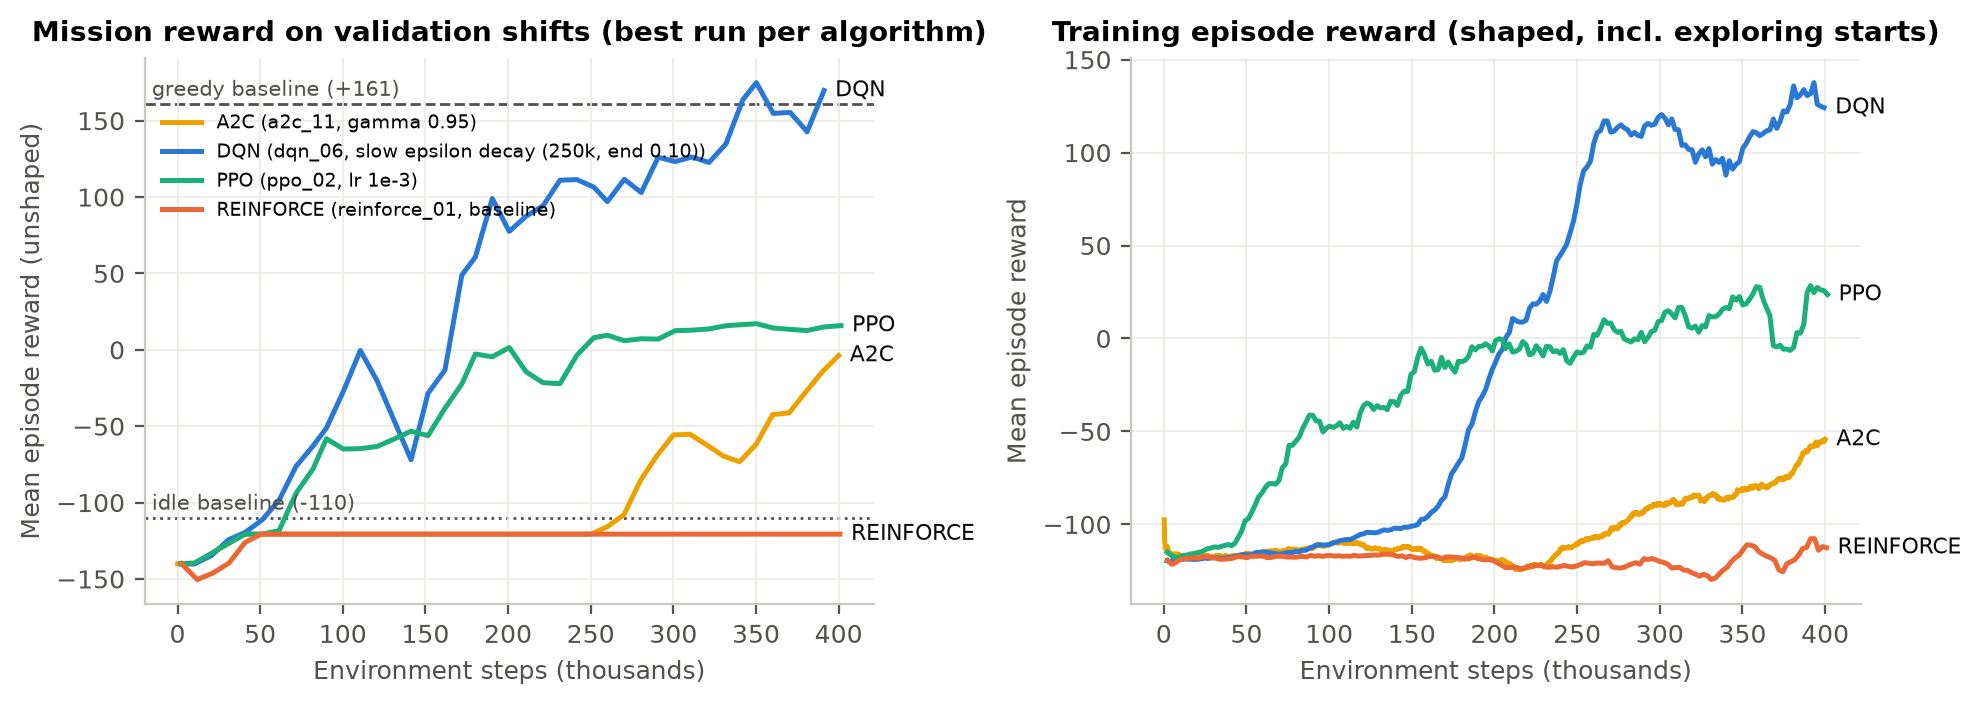

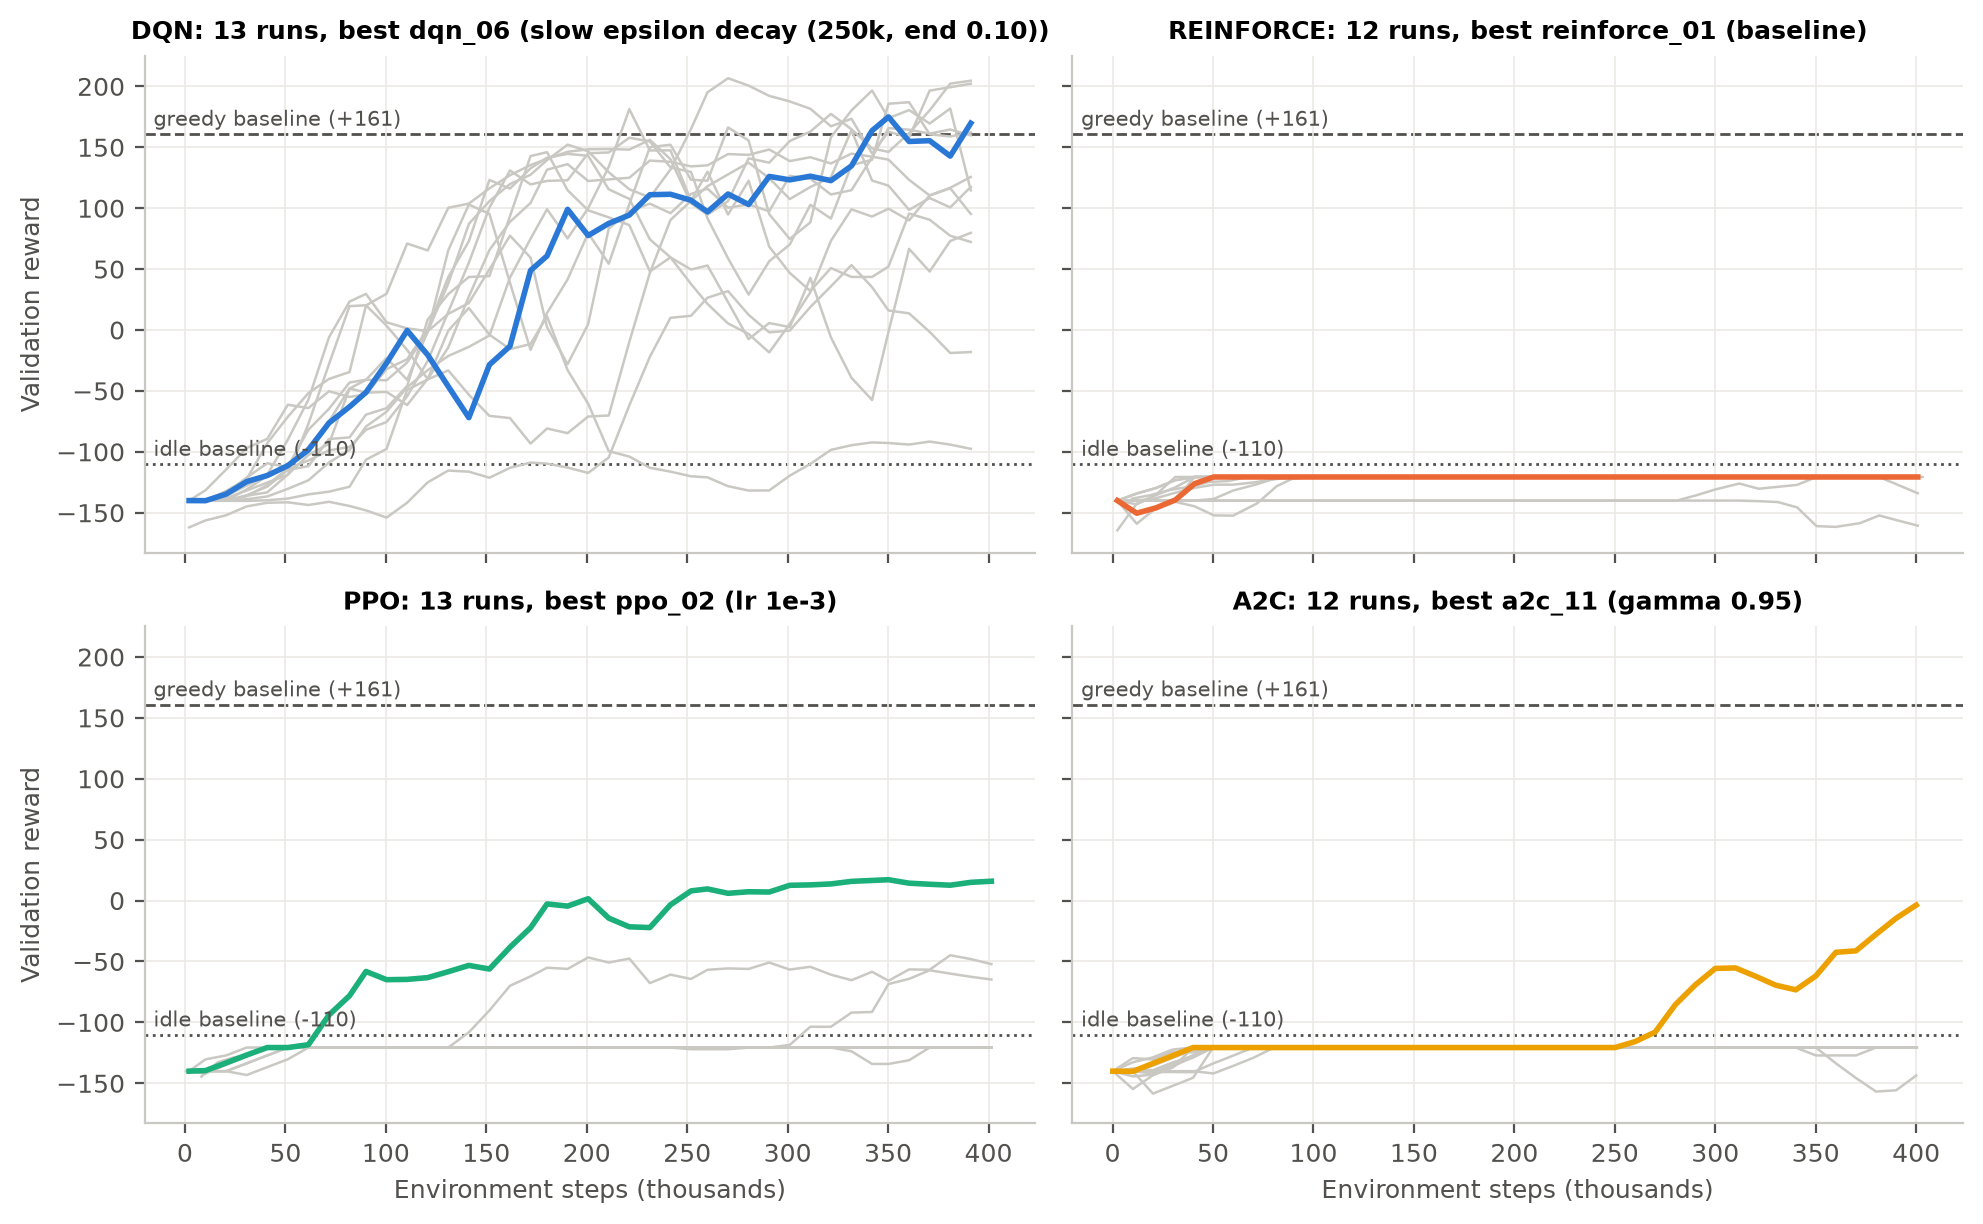

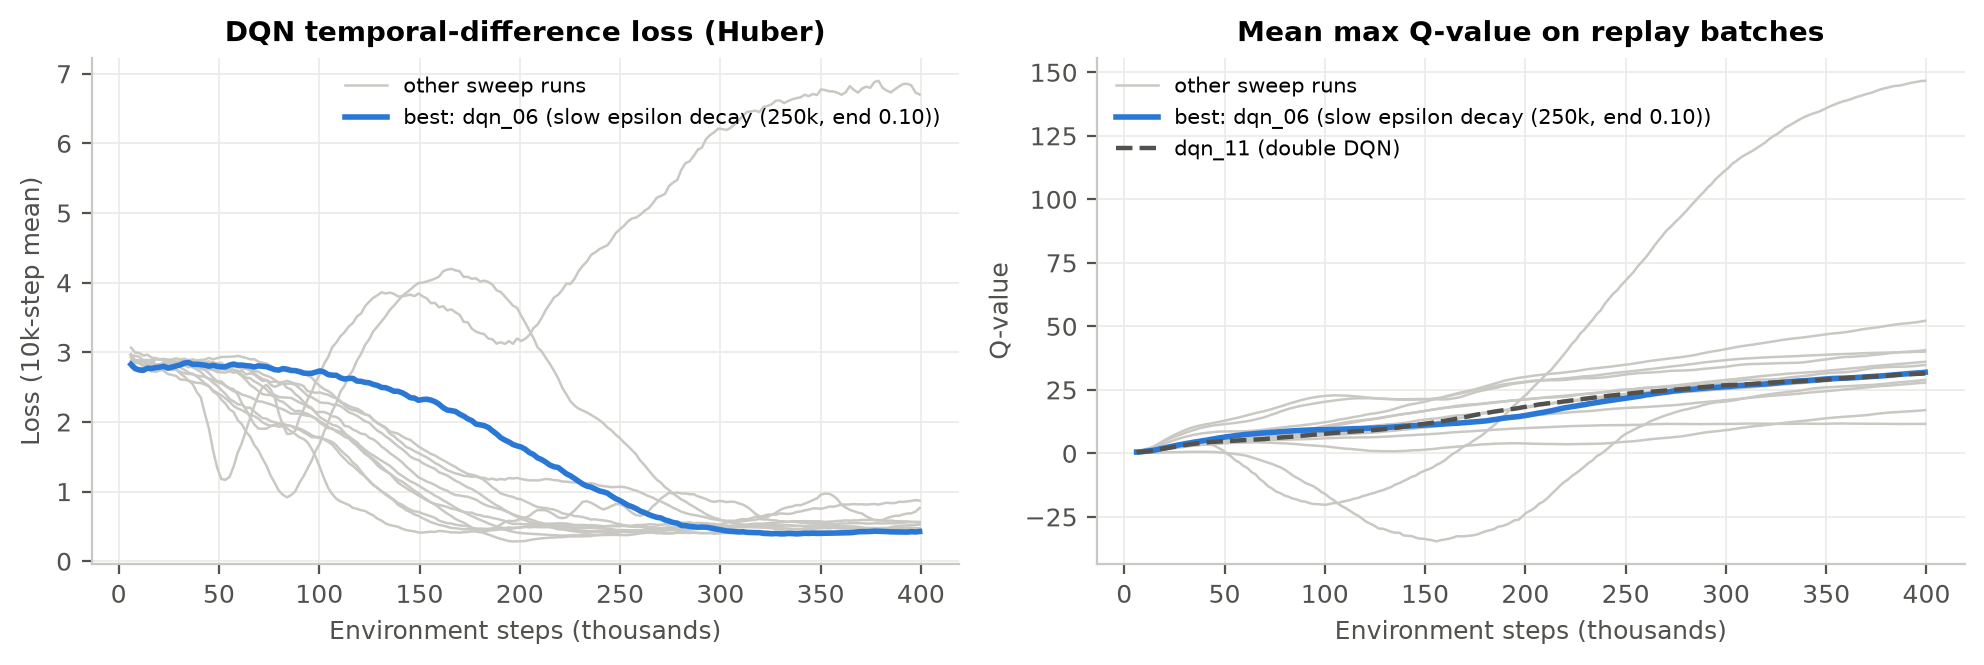

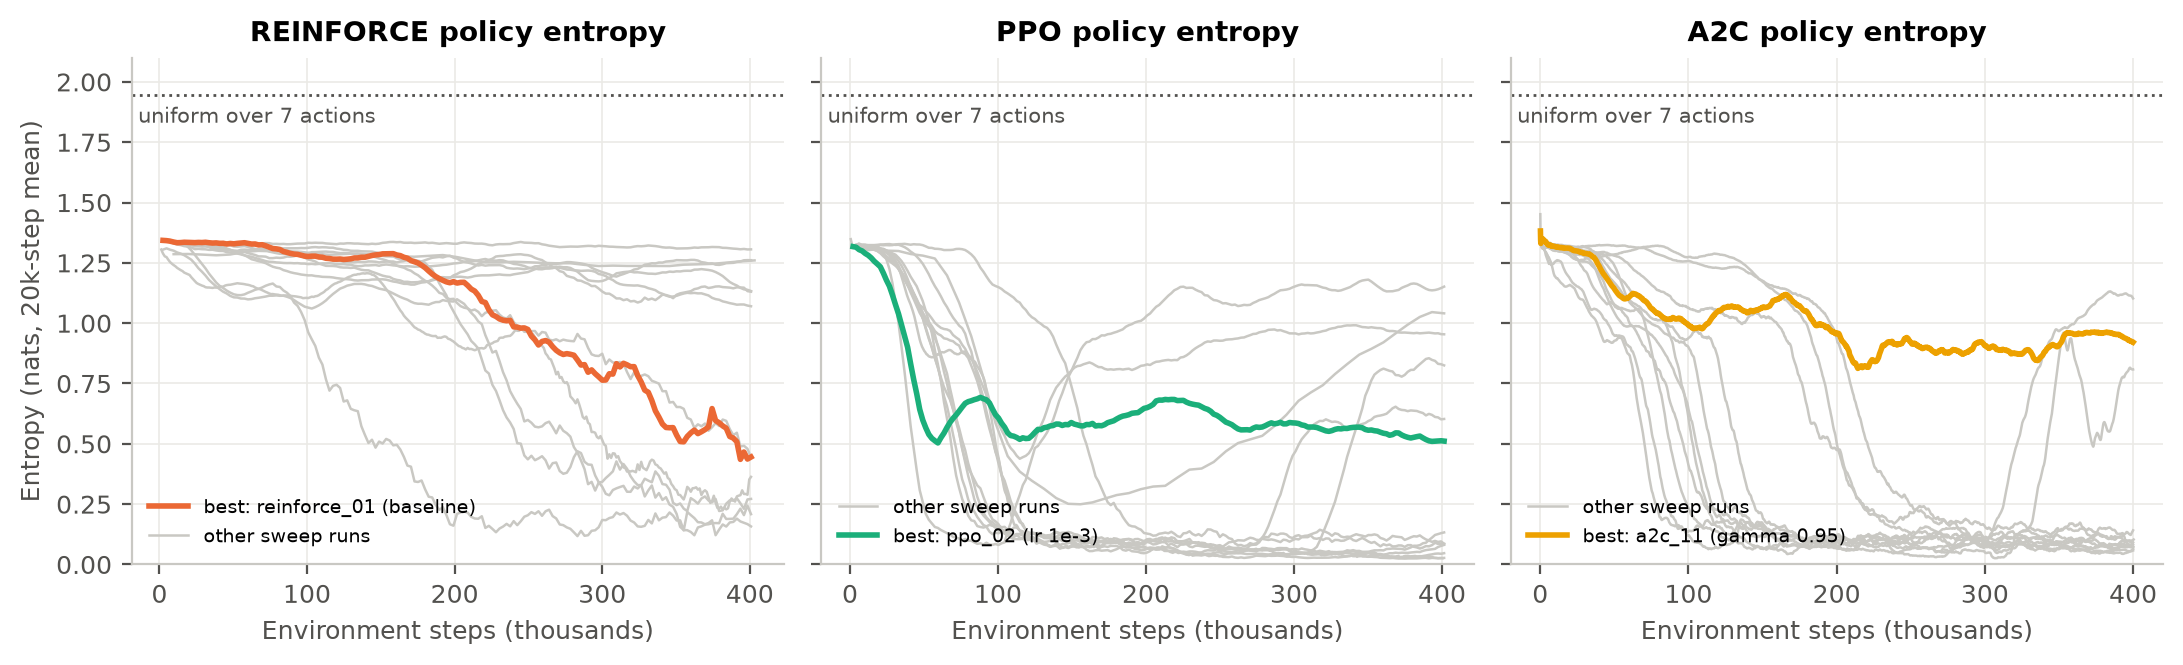

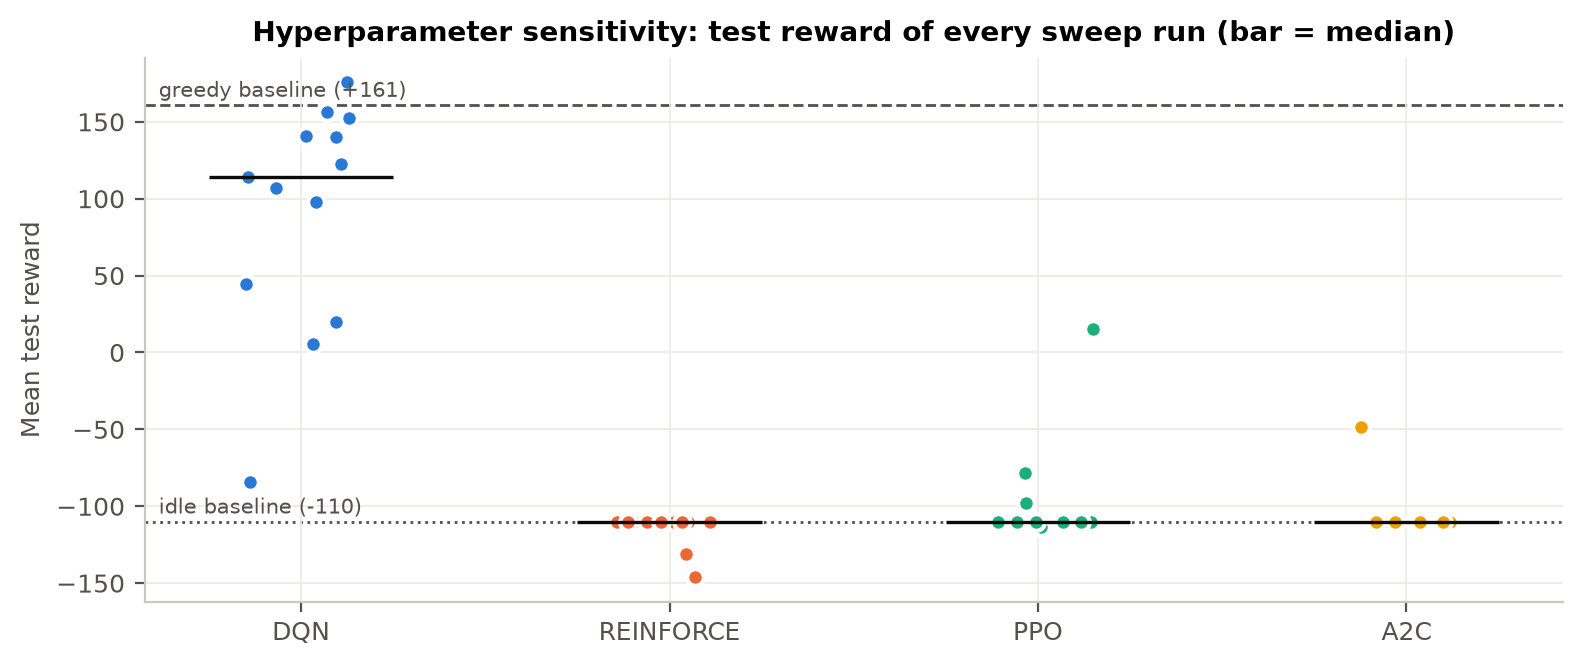

In [8]:
for figure in ["comparative_rewards", "convergence", "dqn_loss", "pg_entropy", "sweep_sensitivity"]:
    display(Image(filename=str(ASSETS / f"{figure}.png"), width=900))

## Generalisation to unseen demand

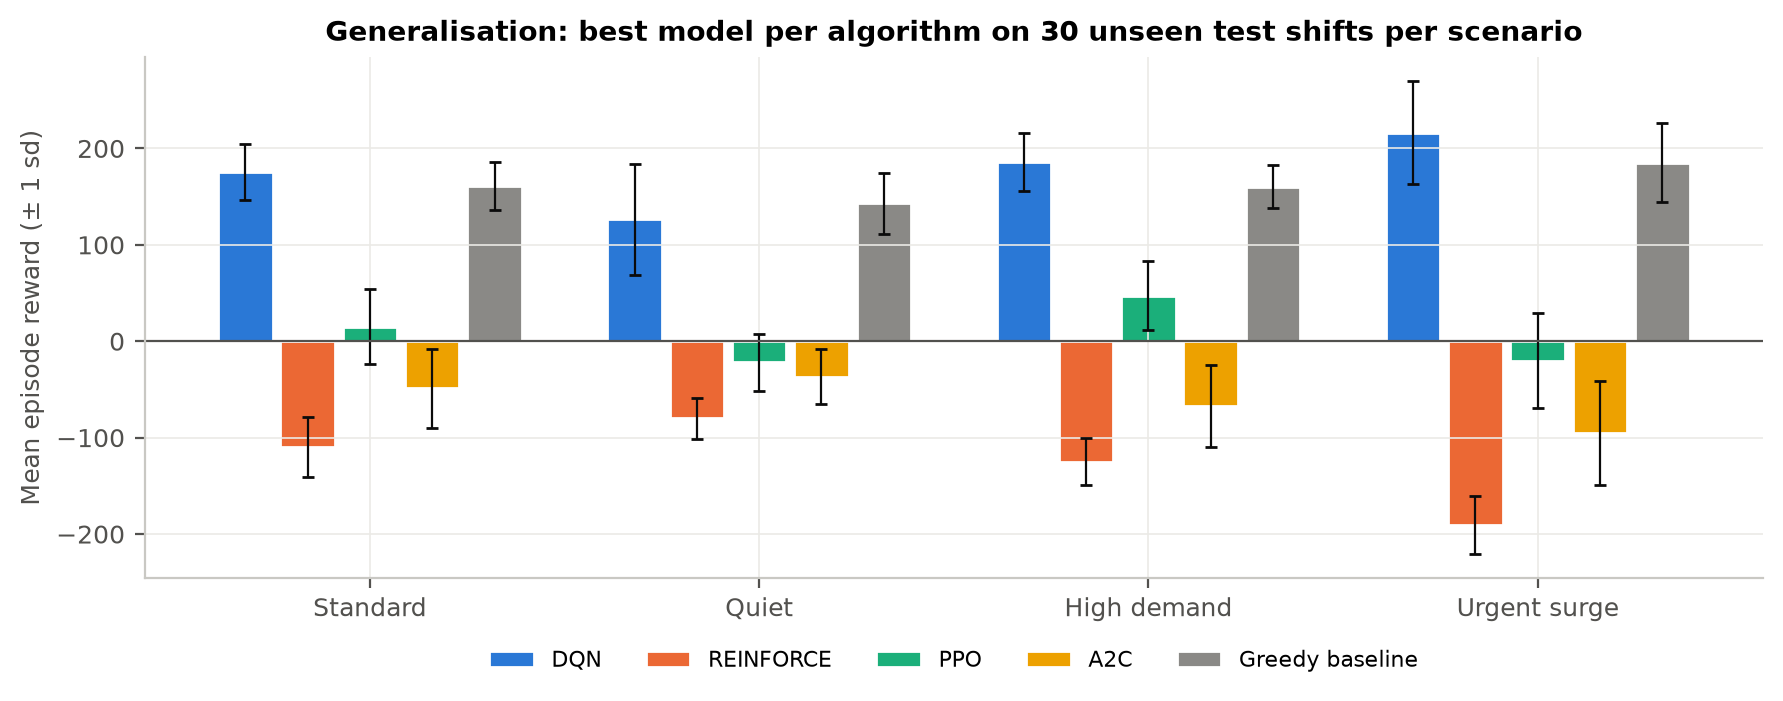

,test_reward,high_demand_reward,urgent_surge_reward
algo,,,
A2C,-48.6,-67.5,-95.4
DQN,175.6,186.1,216.4
PPO,15.2,47.4,-20.3
REINFORCE,-110.2,-124.8,-190.8


In [9]:
display(Image(filename=str(ASSETS / "generalisation.png"), width=900))
best[["test_reward", "high_demand_reward", "urgent_surge_reward"]]

## Seed robustness

The best configuration of each algorithm, retrained with two more random seeds.

In [10]:
robustness = ASSETS / "tables" / "seed_robustness.md"
display(Markdown(robustness.read_text() if robustness.exists() else "_Seed re-runs not finished yet._"))

| algo      | note                                |   seeds |   test_mean |   test_sd_across_seeds |   delivered |   crash_rate |
|:----------|:------------------------------------|--------:|------------:|-----------------------:|------------:|-------------:|
| a2c       | gamma 0.95                          |       3 |      -83.23 |                  36.24 |        1.8  |         0.08 |
| dqn       | slow epsilon decay (250k, end 0.10) |       3 |      164.99 |                  14.22 |       21.37 |         0.01 |
| ppo       | lr 1e-3                             |       3 |       14.37 |                   1.36 |       10.16 |         0    |
| reinforce | baseline                            |       3 |     -110.17 |                   0    |        0    |         0    |

## Watch the best agent fly a test shift

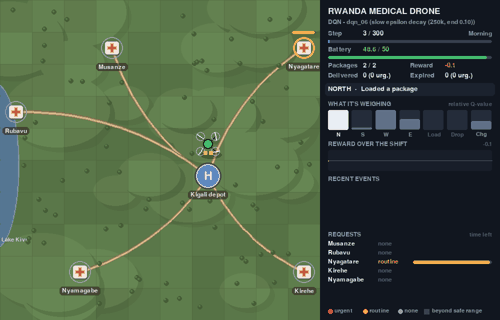

Shift reward +173.7 | delivered 23 (urgent 9) | expired 1 | drone safe


In [11]:
top = best.loc[best["val_reward"].idxmax()]
algo = next(a for a, n in NAMES.items() if n == top.name)
net, _ = load_policy(ROOT / "models" / ("dqn" if algo == "dqn" else "pg") / f"{top['run']}.pt")
policy = scored_policy(net, algo)

env = DroneDeliveryEnv(render_mode="rgb_array")
env.label = f"{top.name} - {top['run']} ({top['note']})"
obs, _ = env.reset(seed=TEST_SEED)
frames, done = [], False
while not done:
    obs, _, terminated, truncated, info = env.step(policy(env, obs))
    done = terminated or truncated
    if env.steps % 3 == 0 and env.steps <= 150:
        frame = env.render()
        frames.append(PILImage.fromarray(frame).resize((frame.shape[1] // 2, frame.shape[0] // 2)))
env.close()

gif = io.BytesIO()
frames[0].save(gif, format="GIF", save_all=True, append_images=frames[1:], duration=110, loop=0)
display(Image(data=gif.getvalue(), format="gif"))
print(f"Shift reward {env.total_reward:+.1f} | delivered {info['delivered']} (urgent {info['urgent_delivered']}) | "
      f"expired {info['expired']} | {'crashed' if info['crashed'] else 'drone safe'}")

## Serving the policy

The same checkpoints sit behind a FastAPI service used by the 3D view (`uv run main.py --view 3d`). Any client can send an observation and get an action back.

In [12]:
from fastapi.testclient import TestClient

from environment.evaluation import greedy
from environment.server import Agent, create_app

client = TestClient(create_app([Agent(top.name, algo, top["run"], net, greedy)], verbose=False))
observation = DroneDeliveryEnv().reset(seed=1)[0].tolist()
print(client.get("/api/meta").json()["agents"])
client.post("/api/act", json={"observation": observation, "agent": top.name}).json()

[{'name': 'DQN', 'label': 'dqn_06', 'color': '#2a78d6'}]


{'agent': 'DQN',
 'action': 4,
 'action_name': 'load',
 'scores': [33.093, 33.465, 33.59, 33.273, 34.051, None, 33.918],
 'score_kind': 'Q-value'}